# Counterfactual detection of deferral type

Machine uncertainty and expected expert performance at each deferred point and at its
counterfactual, with paired tests, and the (ΔU, ΔE) quadrant plots (`fig:counterfactual_distributions`,
`fig:quadrant_results`; appendix `fig:panel_crossentropy` and `fig:panel_ova`).

Reads the validation cache at requested expert accuracy 0.75 (all ten seeds) and the COMPAS
cache: run `validation.ipynb` and `compas.ipynb` first. COMPAS always uses its fitted expert.
Outputs go to `figures/<EXPERT>/`.

In [1]:
EXPERT = "fitted"  # "fitted": the expert fitted by MLE on each training split (paper); "true": the known synthetic expert

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy import stats

import core

OUT = core.FIGURES / EXPERT
OUT.mkdir(parents=True, exist_ok=True)
ACCURACY, SCATTER_SEED = 0.75, 0  # the quadrant plots show one seed; the distributions and tests use all
FILE_PREFIX = {"realizable_surrogate": "realizable_surrogate", "crossentropy_surrogate": "cross_entropy_surrogate",
               "one_vs_all": "one_vs_all"}
FACTUAL_COLOR, COUNTERFACTUAL_COLOR = "#1F77B4", "#C7DDED"

In [3]:
frames = []
for m in core.METHODS:
    for d in core.DATASETS:
        for s in core.SEEDS:
            pairs, _ = core.load_run(core.validation_path(d, m, ACCURACY, s))
            typed = core.assign_types(pairs, core.expert_model(d, ACCURACY, s, EXPERT))
            frames.append(typed.assign(method=m, dataset=d, seed=s))
pairs, _ = core.load_run(core.compas_path(0))
frames.append(core.assign_types(pairs, core.expert_model("compas", None, 0, EXPERT))
              .assign(method="realizable_surrogate", dataset="compas", seed=0))
pairs = pd.concat(frames, ignore_index=True)
pairs = pairs[pairs["found"]].copy()
METRICS = {"entropy": ("uncertainty_x", "uncertainty_cf", "Uncertainty"),
           "expert": ("expert_performance_x", "expert_performance_cf", "Expected Expert Perf.")}

## Paired tests

Two-sided Wilcoxon signed-rank test of the factual minus counterfactual difference: on the ten
within-seed mean differences for the synthetic datasets, on the instance differences for the
single COMPAS run. Holm adjustment across the 20 comparisons.

In [4]:
def star(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"


def wilcoxon(differences):
    differences = np.round(np.asarray(differences, dtype=float), 12)
    if np.all(differences == 0):
        return 1.0
    return float(stats.wilcoxon(differences, alternative="two-sided", zero_method="pratt", method="auto").pvalue)


rows = []
for (m, d), frame in pairs.groupby(["method", "dataset"], sort=False):
    for metric, (factual, counterfactual, _) in METRICS.items():
        difference = frame[factual].astype(float) - frame[counterfactual].astype(float)
        units = difference if d == "compas" else difference.groupby(frame["seed"]).mean()
        rows.append(dict(method=m, dataset=d, metric=metric, n_pairs=len(frame), mean_difference=units.mean(), p_raw=wilcoxon(units)))
tests = pd.DataFrame(rows)
assert len(tests) == 20
order = np.argsort(tests["p_raw"].to_numpy())
holm = np.empty(len(tests))
holm[order] = np.minimum(1, np.maximum.accumulate(tests["p_raw"].to_numpy()[order] * np.arange(len(tests), 0, -1)))
tests["p_holm"] = holm
tests["stars"] = tests["p_holm"].map(star)
P = tests.set_index(["method", "dataset", "metric"])["p_holm"].to_dict()
tests

,method,dataset,metric,n_pairs,mean_difference,p_raw,p_holm,stars
0,realizable_surrogate,adult,entropy,42433,0.042857,1.953125e-03,3.515625e-02,*
1,realizable_surrogate,adult,expert,42433,0.091889,3.906250e-03,3.515625e-02,*
2,realizable_surrogate,plant,entropy,9279,0.017264,1.601562e-01,4.804688e-01,ns
3,realizable_surrogate,plant,expert,9279,0.145511,1.953125e-03,3.515625e-02,*
4,realizable_surrogate,wine,entropy,1507,0.177180,1.953125e-03,3.515625e-02,*
5,realizable_surrogate,wine,expert,1507,0.138563,3.906250e-03,3.515625e-02,*
6,crossentropy_surrogate,adult,entropy,55358,0.020288,4.316406e-01,8.632812e-01,ns
7,crossentropy_surrogate,adult,expert,55358,0.083354,1.953125e-03,3.515625e-02,*
8,crossentropy_surrogate,plant,entropy,11168,0.050883,1.953125e-03,3.515625e-02,*
9,crossentropy_surrogate,plant,expert,11168,0.250813,1.953125e-03,3.515625e-02,*


## Distributions

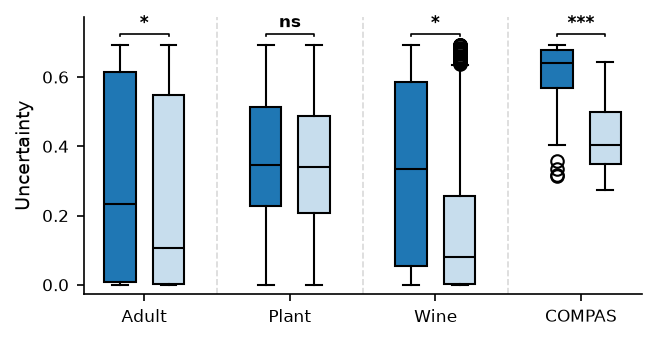

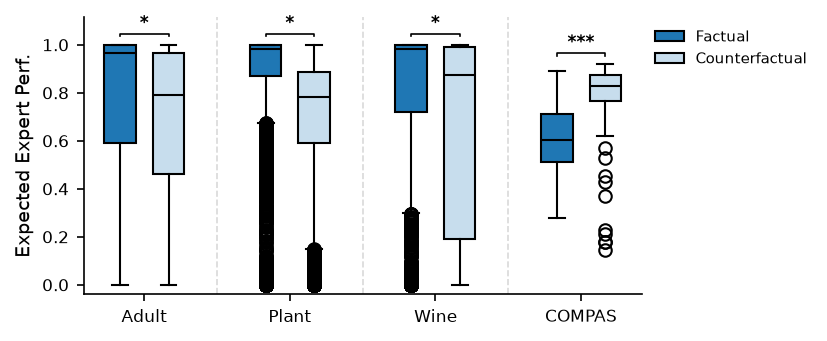

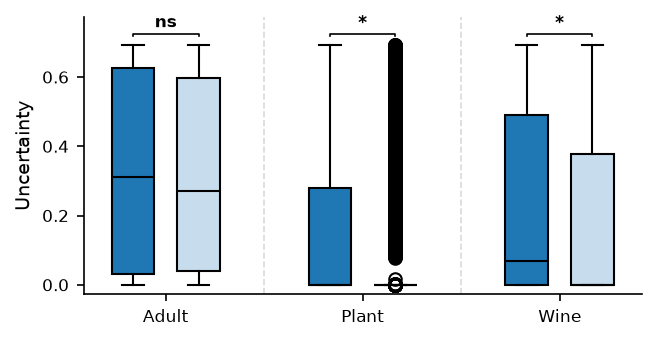

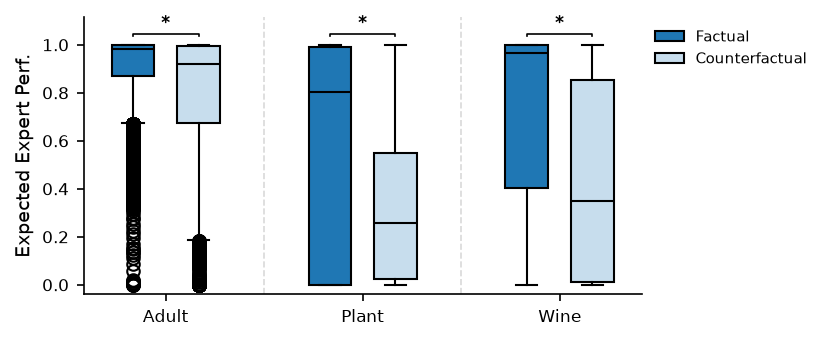

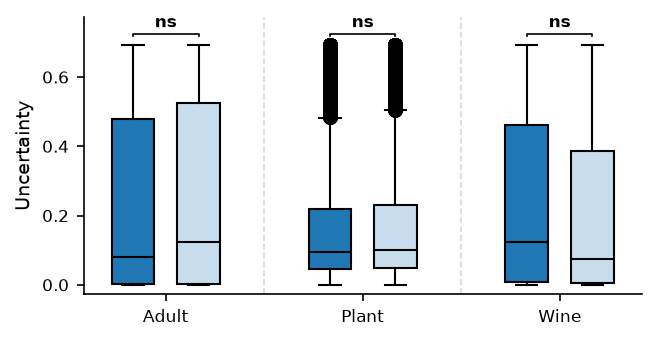

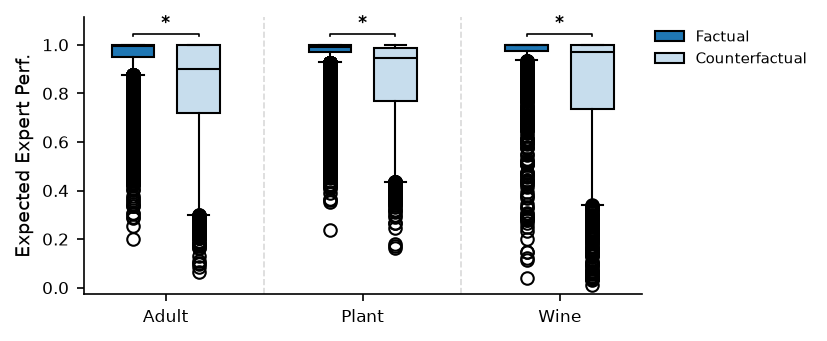

In [5]:
def distribution_panel(ax, frame, method, datasets, metric):
    factual_column, counterfactual_column, label = METRICS[metric]
    centers, tops, values = [], [], []
    for i, d in enumerate(datasets):
        subset = frame[frame["dataset"] == d]
        for position, column, color in ((3 * i, factual_column, FACTUAL_COLOR), (3 * i + 1, counterfactual_column, COUNTERFACTUAL_COLOR)):
            box = ax.boxplot([subset[column].to_numpy()], positions=[position], widths=0.65, patch_artist=True)
            for patch in box["boxes"]:
                patch.set(facecolor=color, edgecolor="black", linewidth=1.0)
            for element in ("whiskers", "caps", "medians", "fliers"):
                for artist in box[element]:
                    artist.set(color="black", linewidth=1.0)
            values.append(subset[column].to_numpy())
        centers.append(3 * i + 0.5)
        tops.append(max(subset[factual_column].max(), subset[counterfactual_column].max()))
    low, high = min(v.min() for v in values), max(v.max() for v in values)
    span = max(high - low, 1e-6)
    for i, d in enumerate(datasets):
        y = tops[i] + 0.045 * span
        ax.plot([3 * i, 3 * i, 3 * i + 1, 3 * i + 1], [y - 0.01 * span, y, y, y - 0.01 * span], color="black", linewidth=0.8)
        ax.text(3 * i + 0.5, y + 0.012 * span, star(P[(method, d, metric)]), ha="center", va="bottom", fontsize=8, fontweight="bold")
    ax.set_xticks(centers)
    ax.set_xticklabels([core.DATASET_LABELS[d] for d in datasets])
    ax.set_ylabel(label)
    ax.set_xlim(-0.75, 3 * len(datasets) - 1.25)
    ax.set_ylim(low - 0.04 * span, max(tops) + 0.045 * span + 0.07 * span)
    ax.tick_params(axis="both", labelsize=8)
    for separator in range(2, 3 * len(datasets) - 1, 3):
        ax.axvline(separator, color="gray", linestyle="--", alpha=0.3, linewidth=0.8)


plt.rcParams.update({"font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42})
for m in core.METHODS:
    datasets = [*core.DATASETS, "compas"] if m == "realizable_surrogate" else list(core.DATASETS)
    frame = pairs[pairs["method"] == m]
    for metric, name in (("entropy", "uncertainty"), ("expert", "expert_performance")):
        fig, ax = plt.subplots(figsize=(4.8, 2.4), dpi=150)
        distribution_panel(ax, frame, m, datasets, metric)
        if metric == "expert":
            ax.legend(handles=[Patch(facecolor=FACTUAL_COLOR, edgecolor="black", label="Factual"),
                               Patch(facecolor=COUNTERFACTUAL_COLOR, edgecolor="black", label="Counterfactual")],
                      frameon=False, bbox_to_anchor=(1, 1.0), fontsize=7)
        fig.savefig(OUT / f"{FILE_PREFIX[m]}_{name}_distributions.pdf", bbox_inches="tight")
        plt.show()

## Quadrants

ΔU = U_M(x) − U_M(x+δ*) and ΔE = E_h(x) − E_h(x+δ*), one seed. Type I is lower right,
Type II upper left, Mixed upper right.

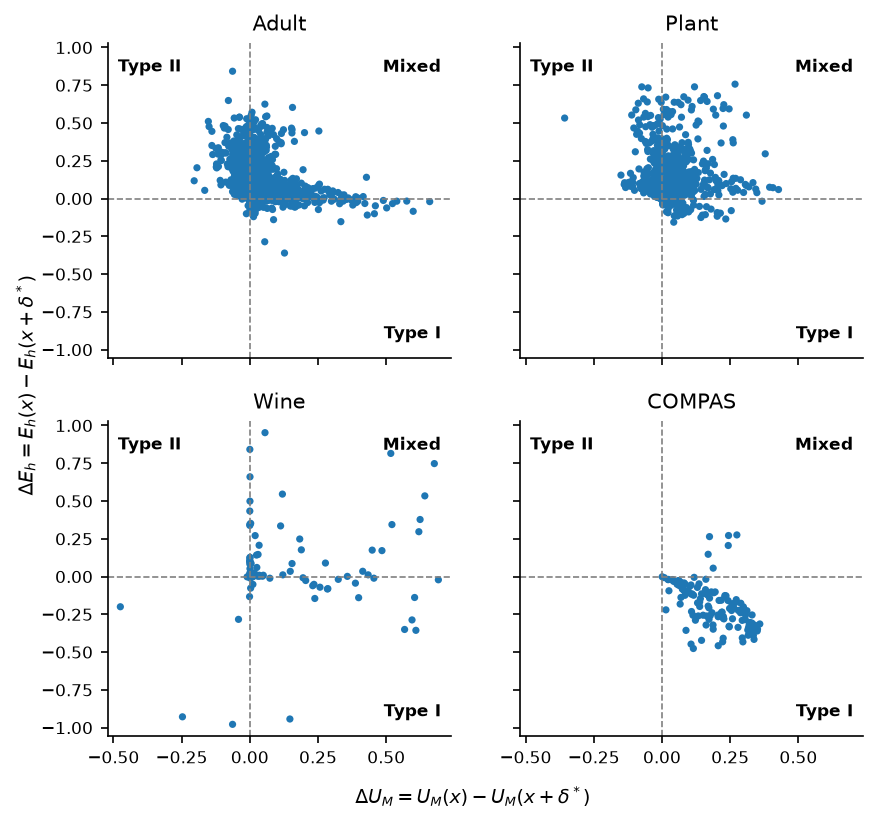

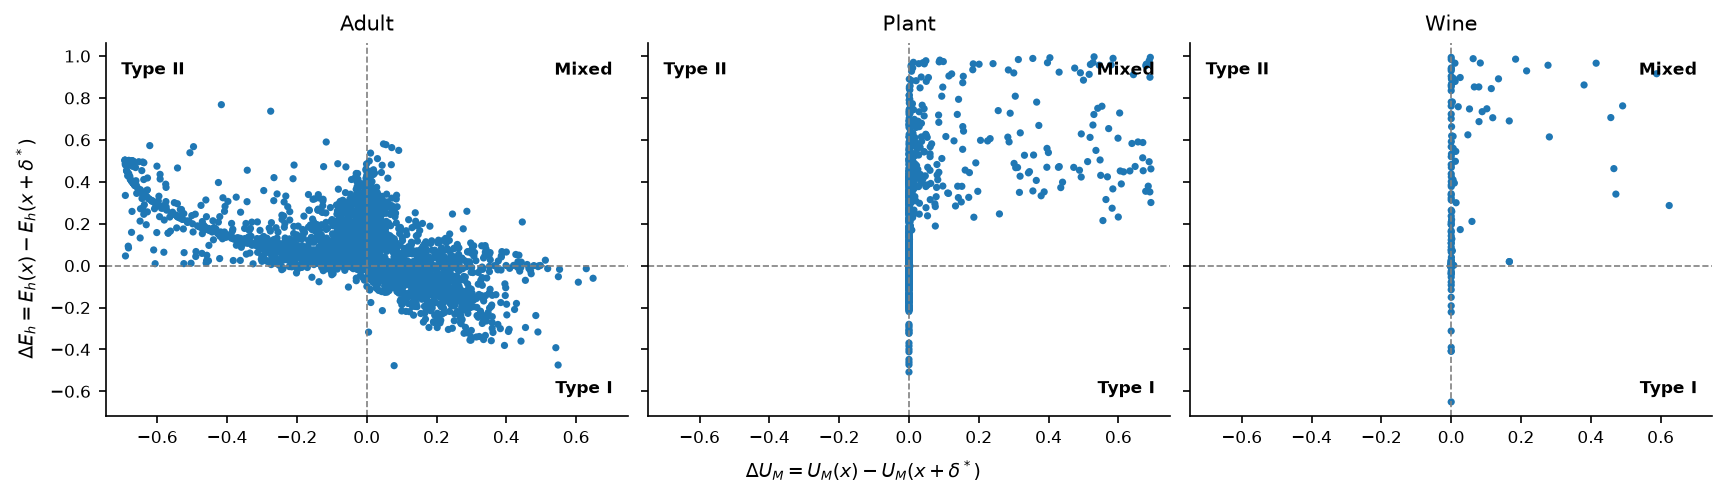

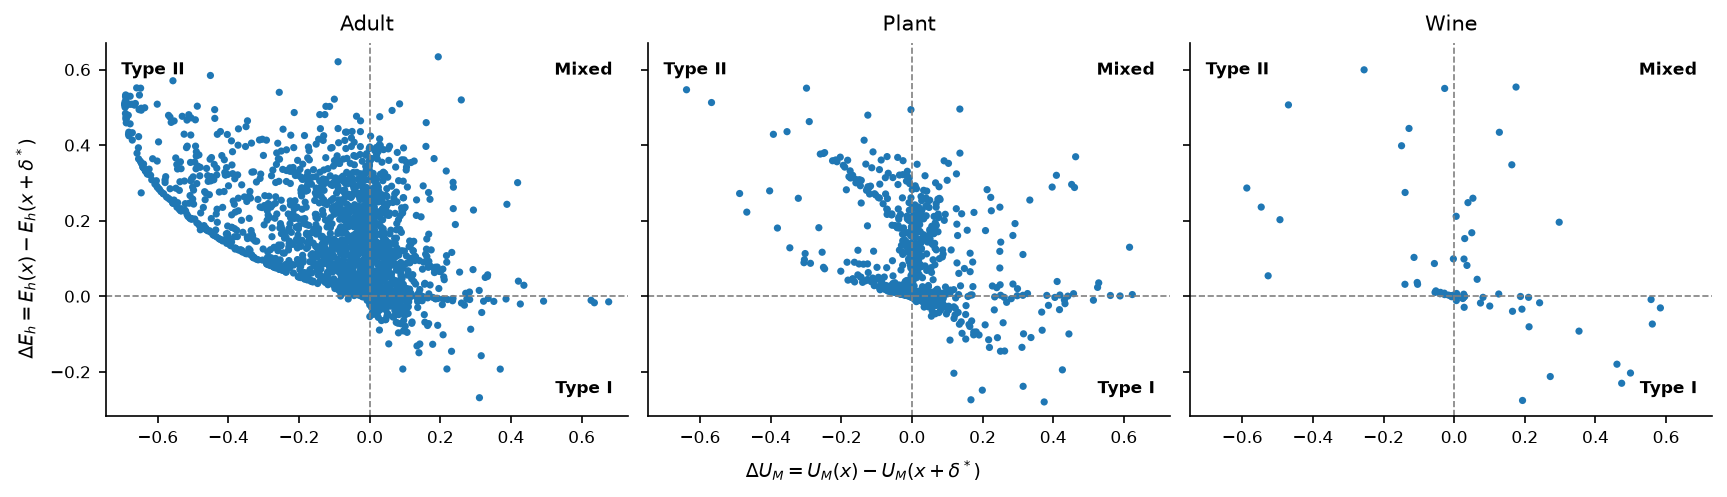

In [6]:
for m in core.METHODS:
    datasets = [*core.DATASETS, "compas"] if m == "realizable_surrogate" else list(core.DATASETS)
    frame = pairs[(pairs["method"] == m) & ((pairs["dataset"] == "compas") | (pairs["seed"] == SCATTER_SEED))]
    delta_u = frame["uncertainty_x"] - frame["uncertainty_cf"]
    delta_e = frame["expert_error_cf"] - frame["expert_error_x"]
    pad_u, pad_e = (0.04 * max(v.max() - v.min(), 1e-6) for v in (delta_u, delta_e))
    grid = dict(nrows=2, ncols=2, figsize=(6.5, 6.0)) if len(datasets) == 4 else dict(nrows=1, ncols=3, figsize=(11.4, 3.2), layout="constrained")
    fig, axes = plt.subplots(**grid, dpi=150, sharex=True, sharey=True)
    for ax, d in zip(axes.flat, datasets):
        rows = frame["dataset"] == d
        ax.scatter(delta_u[rows], delta_e[rows], s=12, color=FACTUAL_COLOR, edgecolors="none")
        ax.axvline(0, linestyle="--", color="gray", linewidth=0.8)
        ax.axhline(0, linestyle="--", color="gray", linewidth=0.8)
        ax.set_xlim(delta_u.min() - pad_u, delta_u.max() + pad_u)
        ax.set_ylim(delta_e.min() - pad_e, delta_e.max() + pad_e)
        ax.set_title(core.DATASET_LABELS[d], fontsize=10)
        ax.tick_params(axis="both", labelsize=8)
        for x, y, label, ha, va in ((0.97, 0.05, "Type I", "right", "bottom"), (0.03, 0.95, "Type II", "left", "top"),
                                    (0.97, 0.95, "Mixed", "right", "top")):
            ax.text(x, y, label, transform=ax.transAxes, ha=ha, va=va, fontsize=8, fontweight="bold")
    position = dict(x=dict(y=0.03), y=dict(x=0.03)) if len(datasets) == 4 else dict(x={}, y={})
    fig.supxlabel(r"$\Delta U_M = U_M(x)-U_M(x+\delta^*)$", fontsize=9, **position["x"])
    fig.supylabel(r"$\Delta E_h = E_h(x)-E_h(x+\delta^*)$", fontsize=9, **position["y"])
    fig.savefig(OUT / f"quadrants_{m}.pdf", bbox_inches="tight")
    plt.show()